# Research notebook: three factor plasticity

**Curated source:** [`notebooks/30_three_factor_stdp_vs_sensory_resources.ipynb`](../notebooks/30_three_factor_stdp_vs_sensory_resources.ipynb). The experimental code and outputs below are preserved as committed; no claim of equivalence to other historical notebooks is implied.

This notebook compares three-factor eligibility-modulated synaptic weights, sensory-replenished **short-term** synaptic resources, and ESCM 2.0 with fading. These are distinct biological/computational mechanisms. Its standard three-factor-STDP model does not intrinsically guarantee fading, and autaptic pre/post spike timing is degenerate.

**Supporting evidence and lineage.** The camera-driven resource mechanism is not ordinary Tsodyks–Markram STD and is not triplet STDP. Numerical results in this notebook are exploratory; see [31](../notebooks/31_sensory_resource_analytical_calibration.ipynb) for the next calibrated SRR experiment and research notebook 08 for its curated copy.

See [research/index.md](index.md) for the full 31-notebook map and definition of the benchmark variants. Run from an environment with the source notebook's original dependencies. The code cells below have **not been re-executed as part of the reorganization**.

# Notebook 30 — Sensory-replenished synaptic resources versus three-factor STDP

## Scientific question

Can two distinct event-driven synaptic mechanisms reproduce **or improve upon** ESCM 2.0's temporary persistence, sensory-dependent fading, and competitive replacement of spatial representations?

We compare **three independently simulated models on the same 9 × 9 spatial network and camera event schedules**:

| Model | Recurrent transmission | Plasticity | Camera-dependent state |
|---|---|---|---|
| **ESCM 2.0 + fading (benchmark)** | `Iexc_post = 8 * support_post` (overwrite) | None | Camera sets `support = 1`; exponential decay |
| **Sensory-replenished resources (SRR)** | **Additive**, `Iexc_post += J0 * U * resource_post` | Activity-dependent depletion, sensory replenishment | Camera adds a fraction of *missing resources*; resources also leak |
| **Three-factor STDP (3F)** | **Additive**, `Iexc_post += w` | Pre/post eligibility, modulator-gated weight plasticity | Camera drives a decaying modulatory signal; learned weight persists |

**Terminology is essential.** SRR is *not* textbook Tsodyks–Markram STD: sensory-triggered replenishment and decay toward zero are model extensions. The 3F model *is* an explicit eligibility × modulation weight update, but on a **self-synapse** it cannot express nontrivial pre–post order, because pre and post spikes coincide. We therefore check a non-autaptic timing example separately. An autaptic comparison is fair for network connectivity but **not** a definitive test of three-factor STDP in general.

### Prior experimental reference

Our benchmark uses the *later approved ESCM 2.0 + fading* (not the earlier Notebook 20 model without fading). Earlier notebooks reported approximately 3/5 replacements on the original five structures, and 4/8 on an extended eight-structure suite. **These are historical reference values, not assertions about this run.** This notebook recomputes the benchmark under identical stimuli.

**Hypotheses:** SRR should have an analytically guaranteed loss of recurrent efficacy without camera events; 3F does **not** guarantee this without some additional forgetting or homeostatic mechanism. Either could nevertheless have better competition under tested conditions. Model selection uses only development geometries; all other shapes, timing conditions, and timesteps are held out from selection.

**Execution:** Python/NumPy Brian2 backend, chosen because the experiment consists of many short simulations and a separate C++ build per run would be inefficient. Simulations execute when you run the notebook in your Brian2 environment. The exported notebook contains no fabricated numerical results.

## 1. Dynamical models and mathematical expectations

All three models use the same dimensionless current-based LIF neuron:

\[
\tau_m\dot v_i=-v_i+I_{\mathrm{ext},i}+I_{\mathrm{exc},i}-I_{\mathrm{inh},i},
\qquad \tau_a\dot I_{a,i}=-I_{a,i},\quad a\in\{\mathrm{ext,exc,inh}\}.
\]

At threshold \(v>1\), the membrane resets to zero. The camera-to-neuron input is **additive** (`Iext += 22`) for every model. Lateral inhibition is additive with the *same* surround weights, distances \(1.5<d\le5.5\), baseline \(0.1\exp[-d^2/(2\times2.5^2)]\). Both new candidates use a 1 ms absolute refractory period; the benchmark retains its original 0 ms period. Currents continue to decay while neurons are refractory.

### Sensory-replenished resources (SRR)

A bounded *per-autapse* resource \(x\in[0,1]\) follows

\[
\dot x=-x/\tau_x,\quad
x\leftarrow x+\alpha(1-x)\ \text{(camera event)},\quad
I_{\rm exc}\leftarrow I_{\rm exc}+J_0 Ux,\;x\leftarrow(1-U)x\ \text{(autapse spike)}.
\]

A camera event replenishes missing resources, while self-spikes consume them. These are *two distinct pathways*, so the model is better described as **sensory-modulated short-term synaptic efficacy with use-dependent depression**, not ordinary STD. Because there is exactly one autapse per neuron, a neuron-resident variable `resource` is mathematically identical to storing one copy on its autapse and allows the camera synapse to update it directly.

**Bound:** after the last camera event at \(t_0\), \(x(t)\le x(t_0)e^{-(t-t_0)/\tau_x}\) even in the presence of recurrent spikes. With positive refractory time and finite current decay, recurrent input necessarily vanishes, so firing stops in the absence of other ongoing excitation.

### Three-factor STDP (3F)

A synapse stores an eligibility trace \(e\), pre/post traces \(p,q\), and a **learned weight** \(w\):

\[
\dot p=-p/\tau_p,\;\dot q=-q/\tau_q,\;\dot e=-e/\tau_{\rm elig},\;
\dot m=-m/\tau_{\rm mod}.
\]

Pre-spikes add \(A_-q\) to eligibility; post-spikes add \(A_+p\). Camera events increase \(m\), and on recurrent spikes the eligibility-weight update is \(w\leftarrow\operatorname{clip}(w+\eta m e,w_{\min},w_{\max})\). Transmission is additive \(I_{\rm exc}\leftarrow I_{\rm exc}+w\). Thus **plasticity depends on all three factors** (pre/post correlation and a camera-driven modulator). The weight has **no explicit decay**: if activity ceases, a learned strong synapse can remain strong. That difference from SRR is part of the test, not a bug.

We use the same spike schedule and inhibition geometry; we do **not** introduce local inter-neuron excitation simply to make STDP work.

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


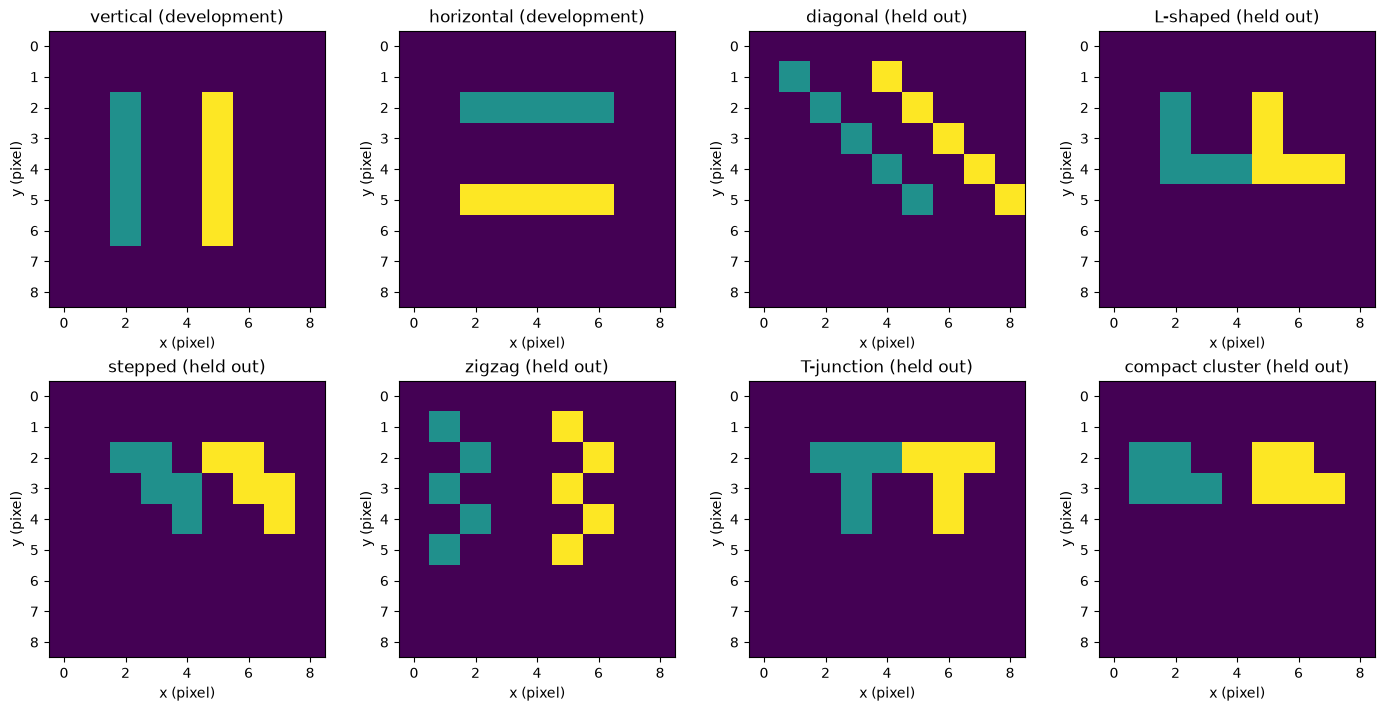

Spatial network: 81 neurons; 3620 surround inhibitory synapses


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from itertools import product
import brian2 as b2

b2.prefs.codegen.target = "numpy"
width = height = 9
n = width * height
dt_ms = 0.05
xy = np.column_stack((np.arange(n) % width, np.arange(n) // width))

def pixels(coords):
    return np.array([y*width + x for x, y in coords], dtype=int)

shapes = {
    "vertical": (pixels([(2, y) for y in range(2, 7)]), pixels([(5, y) for y in range(2, 7)])),
    "horizontal": (pixels([(x, 2) for x in range(2, 7)]), pixels([(x, 5) for x in range(2, 7)])),
    "diagonal": (pixels([(x, x) for x in range(1, 6)]), pixels([(x+3, x) for x in range(1, 6)])),
    "L-shaped": (pixels([(2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]),
                 pixels([(5, 2), (5, 3), (5, 4), (6, 4), (7, 4)])),
    "stepped": (pixels([(2, 2), (3, 2), (3, 3), (4, 3), (4, 4)]),
                pixels([(5, 2), (6, 2), (6, 3), (7, 3), (7, 4)])),
    "zigzag": (pixels([(1, 1), (2, 2), (1, 3), (2, 4), (1, 5)]),
               pixels([(5, 1), (6, 2), (5, 3), (6, 4), (5, 5)])),
    "T-junction": (pixels([(2, 2), (3, 2), (4, 2), (3, 3), (3, 4)]),
                   pixels([(5, 2), (6, 2), (7, 2), (6, 3), (6, 4)])),
    "compact cluster": (pixels([(1, 2), (2, 2), (1, 3), (2, 3), (3, 3)]),
                        pixels([(5, 2), (6, 2), (5, 3), (6, 3), (7, 3)])),
}
development = ("vertical", "horizontal")
validation = tuple(name for name in shapes if name not in development)
assert len(validation) == 6
for old, new in shapes.values():
    assert len(old) == len(new) == 5 and len(np.unique(np.r_[old, new])) == 10

distance = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
post, pre = np.where((distance > 1.5) & (distance <= 5.5))
base_inhibition = 0.1*np.exp(-distance[post, pre]**2/(2*2.5**2))

fig, ax = plt.subplots(2, 4, figsize=(14, 7), constrained_layout=True)
for a, (name, (old, new)) in zip(ax.flat, shapes.items()):
    img = np.zeros(n, dtype=int)
    img[old], img[new] = 1, 2
    a.imshow(img.reshape(height, width), cmap="viridis", vmin=0, vmax=2, interpolation="nearest")
    a.set(title=f"{name} ({'development' if name in development else 'held out'})",
          xlabel="x (pixel)", ylabel="y (pixel)")
plt.show()
print(f"Spatial network: {n} neurons; {len(pre)} surround inhibitory synapses")

## 2. Analytical checks before simulation

The resource model should satisfy two properties without reference to Brian2: (i) camera replenishment and recurrent depletion preserve \([0,1]\), and (ii) once the camera stops, recurrent spikes can only accelerate resource loss. For a periodic spike train with minimum interval \(t_{\rm ref}\), a bounded spike increment \(J_{\max}\) also implies

\[
I_{\rm exc}^+\le \frac{J_{\max}}{1-e^{-t_{\rm ref}/\tau_{\rm exc}}}.
\]

This is a **finite bound**, not a guarantee of a useful current or biological firing rate. The LIF membrane is also bounded under bounded inputs and resets. We check the resource inequality on arbitrary synthetic event times using elementary NumPy arithmetic. We separately show why conventional STDP on a self-synapse cannot determine which neuron fired first: they are the *same neuron*.

In [2]:
alpha, U, tau_resource = 0.4, 0.12, 100.0
camera_times = np.array([2., 4., 6.])
recurrent_times = np.array([3., 5., 7., 9., 12., 17., 23., 38.])
events = sorted([(t, 0) for t in camera_times] + [(t, 1) for t in recurrent_times])
x, tprev = 0., 0.
records = []
for t, kind in events:
    x *= np.exp(-(t-tprev)/tau_resource)
    if kind == 0:
        x += alpha*(1-x)
    else:
        x *= (1-U)
    records.append((t, kind, x))
    tprev = t
assert all(0 <= row[2] <= 1 for row in records)
x_at_last_camera = next(v for t, kind, v in records if t == camera_times[-1] and kind == 0)
for t, kind, value in records:
    if t >= camera_times[-1]:
        assert value <= x_at_last_camera*np.exp(-(t-camera_times[-1])/tau_resource) + 1e-12
print("PASS: resources bounded and no-input exponential upper bound holds for the tested events")
print("For a 1 ms refractory period and 5 ms excitation decay, the maximum current gain is",
      round(1/(1-np.exp(-1/5)), 3), "times the maximum recurrent increment.")
print("An autapse has t_pre = t_post at every recurrent spike; its STDP timing differences are zero.")

PASS: resources bounded and no-input exponential upper bound holds for the tested events
For a 1 ms refractory period and 5 ms excitation decay, the maximum current gain is 5.517 times the maximum recurrent increment.
An autapse has t_pre = t_post at every recurrent spike; its STDP timing differences are zero.


## 3. Brian2 implementation — the same neurons and graph for every model

The simulation function follows the conventions of Notebooks 28–29: one `NeuronGroup`, a `SpikeGeneratorGroup` for camera events, a one-to-one camera synapse, one recurrent autapse per neuron, and the same surround inhibitory graph. A `SpikeMonitor` always measures firing; optional `StateMonitor`s provide currents and plasticity traces for diagnostics.

For the **three-factor rule**, the recurrent synapse stores its own pre/post/eligibility traces and weight. Eligibility and learning are updated on recurrent spikes using a camera-controlled modulatory trace. This is an **event-sampled** three-factor rule (not a continuous \(\dot w=me\) solver). Its update order is explicitly set: presynaptic pathway order \(-1\), postsynaptic order \(0\). On the autapse, this convention produces deterministic but **timing-degenerate** eligibility. A separate non-autaptic analytical check below demonstrates sensitivity to genuine pre/post order.

In SRR, each neuron has precisely one autapse, so neuron variable `resource` is the local state of that unique synapse. It is *not* the original ESCM sensory-support variable: unlike support, it is depleted by recurrent spikes and replenished fractionally by camera events.

In [3]:
old_pulses = (2., 4., 6.)
def pulse_schedule(old, new=None, second_start=20., stagger=0.):
    schedule = [(np.asarray(old, dtype=int), old_pulses, float(stagger))]
    if new is not None:
        schedule.append((np.asarray(new, dtype=int),
                         (second_start, second_start+2., second_start+4.), float(stagger)))
    return schedule

def simulate(schedule, *, mode, duration_ms=180., n_neurons=n, dt=dt_ms,
             refractory_ms=1., J0=6., U=0.10, alpha=0.5, tau_resource_ms=100.,
             w_init=3., eta=0.03, tau_mod_ms=60., w_max=9.,
             inhibition_gain=1., tau_inh_ms=12., tau_exc_ms=5.,
             tau_m_ms=10., trace_ids=None):
    b2.start_scope()
    b2.defaultclock.dt = dt*b2.ms
    ids, times = [], []
    for group_ids, pulses, stagger in schedule:
        for pulse in pulses:
            for k, pixel in enumerate(group_ids):
                ids.append(int(pixel))
                times.append(float(pulse)+k*stagger)
    order = np.argsort(times, kind="stable")
    camera = b2.SpikeGeneratorGroup(n_neurons,
                                   np.asarray(ids, dtype=int)[order],
                                   np.asarray(times)[order]*b2.ms)
    params = dict(tau_m=float(tau_m_ms)*b2.ms, tau_ext=3*b2.ms,
                  tau_exc=float(tau_exc_ms)*b2.ms,
                  tau_inh=float(tau_inh_ms)*b2.ms,
                  tau_support=120*b2.ms, tau_resource=float(tau_resource_ms)*b2.ms,
                  tau_mod=float(tau_mod_ms)*b2.ms,
                  camera_gain=22., v_threshold=1.)
    eqs = """
        dv/dt = (-v + Iext + Iexc - Iinh)/tau_m : 1
        dIext/dt = -Iext/tau_ext : 1
        dIexc/dt = -Iexc/tau_exc : 1
        dIinh/dt = -Iinh/tau_inh : 1
    """
    if mode == "reference":
        eqs += "dsupport/dt = -support/tau_support : 1\n"
    elif mode == "resource":
        eqs += "dresource/dt = -resource/tau_resource : 1\n"
    elif mode == "three_factor":
        eqs += "dmodulator/dt = -modulator/tau_mod : 1\n"
    else:
        raise ValueError(mode)
    neurons = b2.NeuronGroup(
        n_neurons, eqs, threshold="v > v_threshold", reset="v = 0",
        refractory=(float(refractory_ms)*b2.ms if refractory_ms else False),
        method="exact", namespace=params)
    camera_update = "Iext_post += camera_gain"
    if mode == "reference":
        camera_update += "; support_post = 1"
    elif mode == "resource":
        camera_update += "; resource_post += alpha*(1-resource_post)"
    else:
        camera_update += "; modulator_post += 0.5*(1-modulator_post)"
    camera_synapses = b2.Synapses(camera, neurons, on_pre=camera_update,
                                  namespace={**params, "alpha": float(alpha)})
    camera_synapses.connect(j="i")

    if mode == "reference":
        recurrence = b2.Synapses(neurons, neurons,
                                 on_pre="Iexc_post = 8*support_post")
    elif mode == "resource":
        recurrence = b2.Synapses(
            neurons, neurons,
            on_pre="""Iexc_post += J0*utilization*resource_post
                      resource_post *= (1-utilization)""",
            namespace={"J0": float(J0), "utilization": float(U)})
    else:
        recurrence = b2.Synapses(
            neurons, neurons,
            """w : 1
               dpretrace/dt = -pretrace/(20*ms) : 1 (event-driven)
               dposttrace/dt = -posttrace/(20*ms) : 1 (event-driven)
               deligibility/dt = -eligibility/(50*ms) : 1 (event-driven)""",
            on_pre="""Iexc_post += w
                      eligibility += -0.02*posttrace
                      pretrace += 1
                      w = clip(w + learning_rate*modulator_post*eligibility, 0, max_weight)""",
            on_post="""eligibility += 0.03*pretrace
                       posttrace += 1""",
            namespace={"learning_rate": float(eta), "max_weight": float(w_max)})
    recurrence.connect(i=np.arange(n_neurons), j=np.arange(n_neurons))
    if mode == "three_factor":
        recurrence.w = float(w_init)
        recurrence.pre.order = -1
        recurrence.post.order = 0
    if mode == "resource":
        neurons.resource = 0.
    if mode == "three_factor":
        neurons.modulator = 0.

    spike_monitor = b2.SpikeMonitor(neurons)
    network_objects = [camera, neurons, camera_synapses, recurrence, spike_monitor]
    if n_neurons == n:
        inhibition = b2.Synapses(neurons, neurons, "w : 1", on_pre="Iinh_post += w")
        inhibition.connect(i=pre, j=post)
        inhibition.w = base_inhibition*inhibition_gain
        network_objects.append(inhibition)
    if trace_ids is not None:
        neuron_vars = ["v", "Iext", "Iexc", "Iinh"]
        if mode == "reference": neuron_vars.append("support")
        if mode == "resource": neuron_vars.append("resource")
        if mode == "three_factor": neuron_vars.append("modulator")
        state = b2.StateMonitor(neurons, neuron_vars, record=trace_ids)
        network_objects.append(state)
        if mode == "three_factor":
            weights = b2.StateMonitor(recurrence, ["w", "eligibility"], record=trace_ids)
            network_objects.append(weights)

    b2.Network(*network_objects).run(float(duration_ms)*b2.ms)
    out = dict(t=np.asarray(spike_monitor.t/b2.ms),
               i=np.asarray(spike_monitor.i, dtype=int))
    if trace_ids is not None:
        out["time"] = np.asarray(state.t/b2.ms)
        for v in neuron_vars:
            out[v] = np.asarray(getattr(state, v))
        if mode == "three_factor":
            out["w"] = np.asarray(weights.w)
            out["eligibility"] = np.asarray(weights.eligibility)
    return out

reference = dict(mode="reference", refractory_ms=0.)
print("Simulator and frozen ESCM 2.0 reference are defined.")

Simulator and frozen ESCM 2.0 reference are defined.


## 4. Test the three-factor timing rule on a non-autaptic connection

A genuine pair-based eligibility rule distinguishes causal pre-before-post from post-before-pre spikes. Consider one pre- and one post-spike separated by \(\Delta t\), with exponential pre/post traces (time constant 20 ms). The eligibility increment is

\[
\Delta e = \begin{cases}
+A_+ e^{-\Delta t/\tau_p},& t_{\rm pre}<t_{\rm post},\\
-A_- e^{-(-\Delta t)/\tau_q},& t_{\rm post}<t_{\rm pre}.
\end{cases}
\]

On an autapse, \(t_{\rm pre}=t_{\rm post}\) for each spike, so the sign depends on event ordering rather than neuron-to-neuron causal lag. This is a **structural limitation of the topology**, not something a parameter search can fix. A recurrent network of distinct neurons would be needed to study general three-factor spike-timing learning.

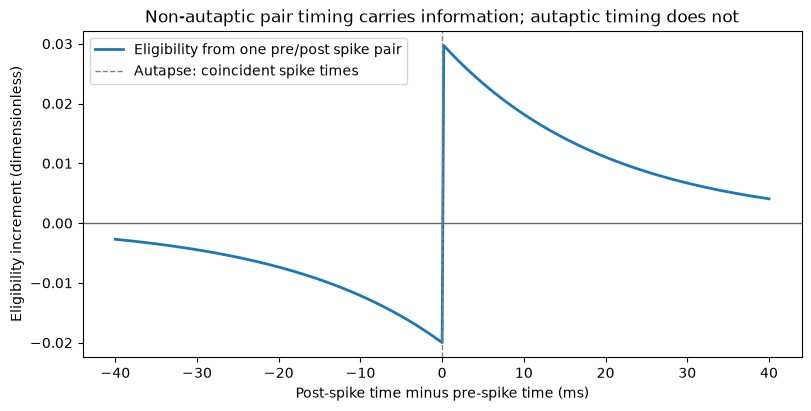

In [4]:
delta = np.linspace(-40., 40., 401)
Aplus, Aminus = 0.03, 0.02
eligibility_pair = np.where(delta > 0, Aplus*np.exp(-delta/20.),
                            -Aminus*np.exp(delta/20.))
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.plot(delta, eligibility_pair, lw=2, label="Eligibility from one pre/post spike pair")
ax.axhline(0, color="0.4", lw=1)
ax.axvline(0, color="0.5", lw=1, ls="--", label="Autapse: coincident spike times")
ax.set(xlabel="Post-spike time minus pre-spike time (ms)",
       ylabel="Eligibility increment (dimensionless)",
       title="Non-autaptic pair timing carries information; autaptic timing does not")
ax.legend()
plt.show()

## 5. Reproduce the benchmark and measure isolated-neuron fading

Stimulate the neuron at 2, 4, and 6 ms, then present **no additional camera events**. Measure last-spike time, spike counts over fixed windows, minimum interspike interval, and direct signs of sustained activity late in the simulation. We do not define success as merely reproducing the benchmark's 89 ms last spike: the objective is useful persistence *and* termination. The historical benchmark should be reproduced before interpreting candidate results.

We use a **bounded development grid**, not an unbounded search. SRR parameters include resource replenishment, use-dependent depletion and leak; 3F parameters include initial weight, learning rate, modulator timescale and allowed maximum weight. All other equations and inhibition stay frozen initially.

In [5]:
solo_schedule = pulse_schedule(np.array([0]))

def solo_metrics(run):
    t = run["t"]
    isi = np.diff(t)
    return dict(total_spikes=len(t),
                last_spike_ms=float(t[-1]) if len(t) else 0.,
                post_camera_spikes=int(np.count_nonzero(t >= 10.)),
                spikes_30_60=int(np.count_nonzero((t >= 30) & (t < 60))),
                spikes_60_120=int(np.count_nonzero((t >= 60) & (t < 120))),
                spikes_180_260=int(np.count_nonzero((t >= 180) & (t < 260))),
                min_isi_ms=float(isi.min()) if len(isi) else np.nan)

solo_reference = simulate(solo_schedule, **reference, n_neurons=1,
                          duration_ms=260., trace_ids=[0])
print("ESCM 2.0 benchmark: ", solo_metrics(solo_reference))

resource_grid = [dict(mode="resource", J0=J0, U=U, alpha=alpha,
                      tau_resource_ms=tr, refractory_ms=1.)
                 for J0, U, alpha, tr in product((12., 24., 40.),
                                                   (0.075, 0.2),
                                                   (0.4, 0.8), (60., 120.))]
three_factor_grid = [dict(mode="three_factor", w_init=w_init, eta=eta,
                          tau_mod_ms=tmod, w_max=9., refractory_ms=1.)
                     for w_init, eta, tmod in product((2., 3., 4., 5.),
                                                     (0.02, 0.15), (30., 120.))]
print(f"Candidate counts: {len(resource_grid)} SRR, {len(three_factor_grid)} 3F")
solo_rows = []
for family, grid in (("SRR", resource_grid), ("3F-STDP", three_factor_grid)):
    for index, cfg in enumerate(tqdm(grid, desc=f"{family} isolated neurons")):
        run = simulate(solo_schedule, **cfg, n_neurons=1, duration_ms=260.)
        solo_rows.append(dict(family=family, candidate=index, **solo_metrics(run)))
solo_table = pd.DataFrame(solo_rows)
display(solo_table.groupby("family")[['last_spike_ms', 'post_camera_spikes', 'spikes_180_260']].describe().round(2))
# Screening is deliberately permissive: avoid immediate extinction and late runaway.
solo_table["screened"] = ((solo_table.post_camera_spikes >= 8) &
                          (solo_table.spikes_30_60 > 0) &
                          (solo_table.spikes_180_260 == 0))
display(solo_table.groupby("family").screened.agg(['sum', 'count']))
print("Note: a failed screening result is still evidence; we do not fabricate a viable candidate.")

ESCM 2.0 benchmark:  {'total_spikes': 54, 'last_spike_ms': 89.2, 'post_camera_spikes': 34, 'spikes_30_60': 12, 'spikes_60_120': 8, 'spikes_180_260': 0, 'min_isi_ms': 0.2499999999999991}
Candidate counts: 24 SRR, 16 3F


SRR isolated neurons:   0%|          | 0/24 [00:00<?, ?it/s]WARNING    The name "tau_resource" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup_1". Will use the object from the group-specific namespace with the value 60. * msecond, but the name also refers to a variable in the run namespace with value '100.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
INFO       Failed to vectorise code, falling back on Python loop: note that this will be very slow! Switch to another code generation target for best performance (e.g. cython). First line is: Iexc_post += _lio_1 * resource_post

last_spike_ms                                                        \
                count    mean   std     min     25%     50%     75%     max   
family                                                                        
3F-STDP          16.0  259.54  0.15  259.10  259.55  259.55  259.55  259.90   
SRR              24.0   20.58  3.56   14.85   18.30   20.50   21.89   28.25   

        post_camera_spikes          ...               spikes_180_260        \
                     count    mean  ...    75%    max          count  mean   
family                              ...                                      
3F-STDP               16.0  249.88  ...  250.0  250.0           16.0  80.0   
SRR                   24.0    7.25  ...    9.0   12.0           24.0   0.0   

                                            
         std   min   25%   50%   75%   max  
family                                      
3F-STDP  0.0  80.0  80.0  80.0  80.0  80.0  
SRR      0.0   0.0   0.0   0.0   0.0   0.0  

[2 rows x 24 columns]

,sum,count
family,,
3F-STDP,0,16
SRR,0,24


Note: a failed screening result is still evidence; we do not fabricate a viable candidate.


## 6. Joint development calibration on vertical and horizontal replacement

The five original structures and the three additional shapes are all *defined* above, but **only vertical and horizontal structures enter parameter selection**. Each experiment includes old-only, new-only, and replacement simulations. The new edge arrives at 20, 22, and 24 ms; the old at 2, 4, and 6 ms. We evaluate two separate 10 ms windows, \([32,42)\) and \([42,52)\) ms, with a minimum of two spikes per pixel per window for isolated persistence.

A valid success requires (i) isolated old and new representations each persist, (ii) all obsolete pixels are silent in *both* competition windows, (iii) every new pixel remains active, and (iv) no off-target activity. This prevents classifying spontaneous fading as inhibition-driven replacement.

**Selection criterion:** first maximize strict replacements, then eligibility, old suppression, new recruitment, and finally minimize off-target activity. We do **not** retune on held-out shapes. The grid is modest to keep execution inspectable. If all candidates fail, report that directly.

In [6]:
def counts(run, ids, a, b):
    mask = (run["t"] >= a) & (run["t"] < b)
    return np.bincount(run["i"][mask], minlength=n)[ids]

def evaluate(geometry, cfg, *, onset=20., stagger=0., dt=dt_ms):
    old, new = shapes[geometry]
    old_schedule = pulse_schedule(old, second_start=onset, stagger=stagger)
    new_schedule = [(new, (onset, onset+2., onset+4.), stagger)]
    duration = max(100., onset+50.+4*stagger)
    old_only = simulate(old_schedule, **cfg, duration_ms=duration, dt=dt)
    new_only = simulate(new_schedule, **cfg, duration_ms=duration, dt=dt)
    combined = simulate(old_schedule+new_schedule, **cfg, duration_ms=duration, dt=dt)
    intervals = [(onset+12.+4*stagger, onset+22.+4*stagger),
                 (onset+22.+4*stagger, onset+32.+4*stagger)]
    outside = np.setdiff1d(np.arange(n), np.r_[old, new])
    def across_windows(run, ids):
        return np.array([counts(run, ids, a, b) for a, b in intervals])
    old_control = (across_windows(old_only, old) >= 2).all(axis=0)
    new_control = (across_windows(new_only, new) >= 2).all(axis=0)
    old_silent = (across_windows(combined, old) == 0).all(axis=0)
    new_active = (across_windows(combined, new) >= 2).all(axis=0)
    off_target = (across_windows(combined, outside) > 0).any(axis=0)
    eligible = bool(old_control.all() and new_control.all())
    passed = bool(eligible and old_silent.all() and new_active.all() and not off_target.any())
    old_spikes_after_onset = combined["t"][(combined["t"] >= onset) &
                                            np.isin(combined["i"], old)]
    last_old_spike = float(old_spikes_after_onset[-1]) if len(old_spikes_after_onset) else np.nan
    return dict(geometry=geometry, eligible=eligible, success=passed,
                old_control=int(old_control.sum()), new_control=int(new_control.sum()),
                old_silent=int(old_silent.sum()), new_active=int(new_active.sum()),
                off_target=int(off_target.sum()), last_old_spike_ms=last_old_spike)

def geometry_table(cfg, geometry_names, **kwargs):
    return pd.DataFrame([evaluate(name, cfg, **kwargs) for name in geometry_names])

benchmark_development = geometry_table(reference, development)
display(benchmark_development)
assert benchmark_development.success.all(), (
    "Reference ESCM 2.0 did not reproduce both development conditions; "
    "verify the reference equations and camera protocol before calibration.")

# Take all screened configurations; when a family has none, test the best two
# for diagnostic purposes and report that screening was not passed.
shortlists = {}
for family, grid in (("SRR", resource_grid), ("3F-STDP", three_factor_grid)):
    rows = solo_table[solo_table.family == family].copy()
    rows = rows.sort_values(['screened', 'spikes_30_60', 'post_camera_spikes'],
                            ascending=[False, False, False])
    keep = rows[rows.screened].head(8)
    if keep.empty:
        keep = rows.head(2)
        print(f"{family}: no candidate passed the isolated-neuron screen; testing 2 diagnostic candidates.")
    shortlists[family] = [grid[int(k)] for k in keep.candidate]

search_rows = []
for family in ('SRR', '3F-STDP'):
    for idx, cfg in enumerate(tqdm(shortlists[family], desc=f"{family} development tests")):
        for gI in (0.75, 1., 1.5):
            setting = {**cfg, 'inhibition_gain': gI}
            result = geometry_table(setting, development)
            search_rows.append(dict(family=family, index=idx, inhibition_gain=gI,
                                    successes=int(result.success.sum()),
                                    eligible=int(result.eligible.sum()),
                                    old_silent=int(result.old_silent.sum()),
                                    new_active=int(result.new_active.sum()),
                                    off_target=int(result.off_target.sum())))
search = pd.DataFrame(search_rows).sort_values(
    ['family', 'successes', 'eligible', 'old_silent', 'new_active', 'off_target'],
    ascending=[True, False, False, False, False, True]).reset_index(drop=True)
display(search.groupby('family').head(8))
locked = {}
for family in ('SRR', '3F-STDP'):
    winner = search[search.family == family].iloc[0]
    locked[family] = {**shortlists[family][int(winner['index'])],
                      'inhibition_gain': float(winner.inhibition_gain)}
    print(f"LOCKED {family}: {locked[family]} — development successes {winner.successes}/2")
print('Held-out geometry and timing lists have not participated in model selection.')

,geometry,eligible,success,old_control,new_control,old_silent,new_active,off_target,last_old_spike_ms
0,vertical,True,True,5,5,5,5,0,22.8
1,horizontal,True,True,5,5,5,5,0,22.8


SRR: no candidate passed the isolated-neuron screen; testing 2 diagnostic candidates.
3F-STDP: no candidate passed the isolated-neuron screen; testing 2 diagnostic candidates.


SRR development tests:   0%|          | 0/2 [00:00<?, ?it/s]WARNING    The name "tau_resource" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup_1". Will use the object from the group-specific namespace with the value 120. * msecond, but the name also refers to a variable in the run namespace with value '100.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of

,family,index,inhibition_gain,successes,eligible,old_silent,new_active,off_target
0,3F-STDP,0,0.75,0,2,0,8,0
1,3F-STDP,1,0.75,0,2,0,8,0
2,3F-STDP,0,1.00,0,2,0,0,0
3,3F-STDP,0,1.50,0,2,0,0,0
4,3F-STDP,1,1.00,0,2,0,0,0
5,3F-STDP,1,1.50,0,2,0,0,0
6,SRR,0,0.75,0,0,10,0,0
7,SRR,0,1.00,0,0,10,0,0
8,SRR,0,1.50,0,0,10,0,0
9,SRR,1,0.75,0,0,10,0,0


LOCKED SRR: {'mode': 'resource', 'J0': 40.0, 'U': 0.075, 'alpha': 0.8, 'tau_resource_ms': 120.0, 'refractory_ms': 1.0, 'inhibition_gain': 0.75} — development successes 0/2
LOCKED 3F-STDP: {'mode': 'three_factor', 'w_init': 2.0, 'eta': 0.15, 'tau_mod_ms': 30.0, 'w_max': 9.0, 'refractory_ms': 1.0, 'inhibition_gain': 0.75} — development successes 0/2
Held-out geometry and timing lists have not participated in model selection.


## 7. Locked spatial generalization — six validation structures

With SRR and three-factor parameter sets now **frozen**, evaluate diagonal, L-shaped, stepped, zigzag, T-junction, and compact-cluster transformations. These shapes are held out *within this notebook's calibration*, although some were explored historically in Notebooks 19–20 and must not be described as wholly new discoveries.

Report all major outcomes instead of reducing performance to a binary score: eligible controls, suppressed old pixels, persistent new pixels, off-target activity, and the last obsolete spike. **A model may be more useful than ESCM 2.0 even if its strict geometry score ties**, provided the other measured properties improve without hidden failures.

Locked spatial generalization:  33%|███▎      | 1/3 [00:03<00:07,  3.64s/it]WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, fi

,model,geometry,eligible,success,old_control,new_control,old_silent,new_active,off_target,last_old_spike_ms
0,ESCM 2.0 + fading,diagonal,True,False,5,5,4,5,0,76.10
1,ESCM 2.0 + fading,L-shaped,True,False,5,5,5,4,0,24.55
2,ESCM 2.0 + fading,stepped,True,True,5,5,5,5,0,25.40
3,ESCM 2.0 + fading,zigzag,True,True,5,5,5,5,0,24.65
4,ESCM 2.0 + fading,T-junction,False,False,4,4,5,4,0,23.95
5,ESCM 2.0 + fading,compact cluster,True,False,5,5,3,5,0,75.55
6,Sensory resources,diagonal,False,False,0,0,5,0,0,22.90
7,Sensory resources,L-shaped,False,False,0,0,5,0,0,24.55
8,Sensory resources,stepped,False,False,0,0,5,0,0,24.05
9,Sensory resources,zigzag,False,False,0,0,5,0,0,24.25


,geometry_passes,eligible,old_silent_pixels,new_active_pixels,off_target_pixels
model,,,,,
ESCM 2.0 + fading,2,5,4.5,4.67,0.0
Sensory resources,0,0,5.0,0.00,0.0
Three-factor STDP,0,6,0.0,3.33,0.0


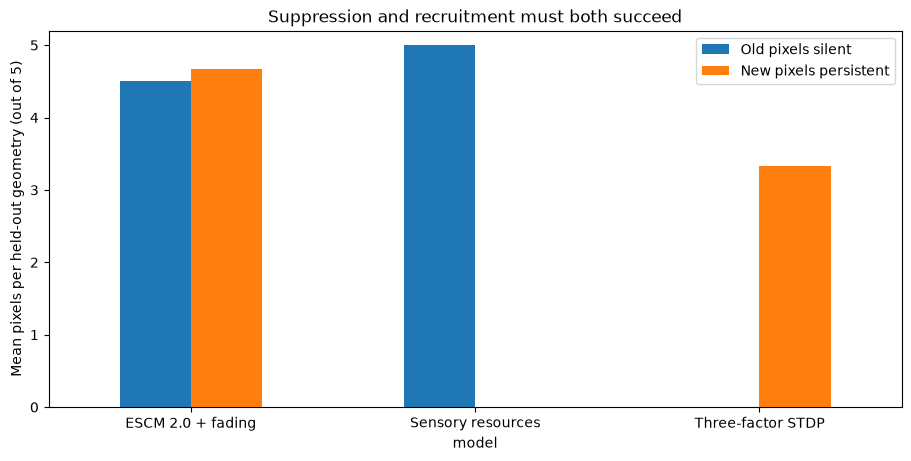

In [7]:
models = {'ESCM 2.0 + fading': reference,
          'Sensory resources': locked['SRR'],
          'Three-factor STDP': locked['3F-STDP']}
results = []
for name, cfg in tqdm(models.items(), desc='Locked spatial generalization'):
    for geometry in validation:
        results.append(dict(model=name, **evaluate(geometry, cfg)))
spatial = pd.DataFrame(results)
display(spatial[['model', 'geometry', 'eligible', 'success', 'old_control',
                 'new_control', 'old_silent', 'new_active', 'off_target',
                 'last_old_spike_ms']].round(2))
summary = spatial.groupby('model').agg(
    geometry_passes=('success', 'sum'), eligible=('eligible', 'sum'),
    old_silent_pixels=('old_silent', 'mean'),
    new_active_pixels=('new_active', 'mean'), off_target_pixels=('off_target', 'mean'))
display(summary.round(2))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
summary[['old_silent_pixels', 'new_active_pixels']].plot.bar(ax=ax, rot=0)
ax.set(ylabel='Mean pixels per held-out geometry (out of 5)',
       title='Suppression and recruitment must both succeed', ylim=(0, 5.2))
ax.legend(['Old pixels silent', 'New pixels persistent'])
plt.show()

## 8. Held-out temporal generalization and numerical resolution

We repeat the vertical replacement at **four second-stimulus onsets** and **four within-edge staggers** (16 conditions), with no parameter changes. A candidate must remain eligible under the isolated controls to receive a strict replacement pass. Next, repeat the six validation geometries at \(\Delta t\in\{0.1,0.05,0.025\}\) ms. Classification agreement across these three steps supports finite numerical robustness but is not a mathematical convergence proof.

Computations are explicitly bounded; `tqdm` indicates progress. Set `RUN_TIMING` or `RUN_TIMESTEP` to `False` only when exploring development cells, and state any omitted validation when interpreting outcomes.

Temporal generalization:  33%|███▎      | 1/3 [00:10<00:21, 10.70s/it]WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first li

,eligible,successes,old_silent,new_active
model,,,,
ESCM 2.0 + fading,13,13,5.0,5.00
Sensory resources,0,0,5.0,0.00
Three-factor STDP,16,0,0.0,2.62


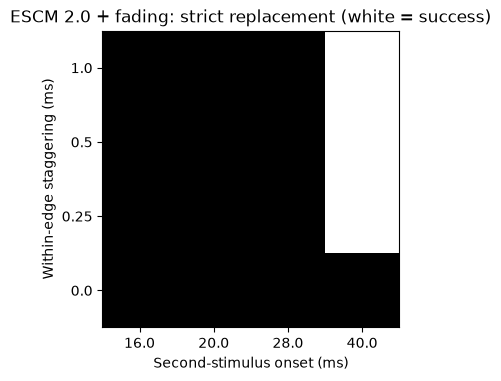

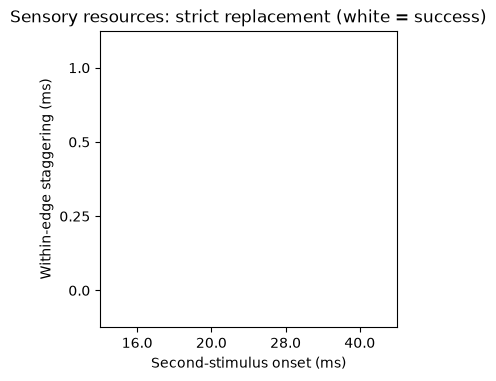

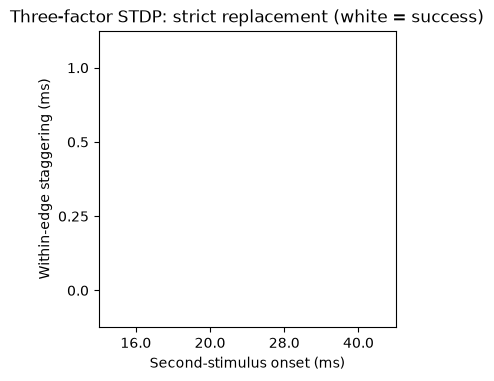

Timestep robustness:   0%|          | 0/3 [00:00<?, ?it/s]WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc

,model,dt_ms,eligible,successes
0,ESCM 2.0 + fading,0.025,5,2
1,ESCM 2.0 + fading,0.050,5,2
2,ESCM 2.0 + fading,0.100,5,2
3,Sensory resources,0.025,0,0
4,Sensory resources,0.050,0,0
5,Sensory resources,0.100,0,0
6,Three-factor STDP,0.025,6,0
7,Three-factor STDP,0.050,6,0
8,Three-factor STDP,0.100,6,0


In [8]:
RUN_TIMING = True
RUN_TIMESTEP = True

if RUN_TIMING:
    timing_rows = []
    for name, cfg in tqdm(models.items(), desc='Temporal generalization'):
        for onset, stagger in product((16., 20., 28., 40.), (0., 0.25, 0.5, 1.)):
            result = evaluate('vertical', cfg, onset=onset, stagger=stagger)
            timing_rows.append(dict(model=name, onset_ms=onset, stagger_ms=stagger, **result))
    timing = pd.DataFrame(timing_rows)
    display(timing.groupby('model').agg(eligible=('eligible', 'sum'),
                                        successes=('success', 'sum'),
                                        old_silent=('old_silent', 'mean'),
                                        new_active=('new_active', 'mean')).round(2))
    for name in models:
        z = timing[timing.model == name].pivot(index='stagger_ms', columns='onset_ms', values='success')
        fig, ax = plt.subplots(figsize=(6, 3.7), constrained_layout=True)
        ax.imshow(z.to_numpy().astype(int), cmap='Greys', origin='lower', vmin=0, vmax=1)
        ax.set(xticks=np.arange(len(z.columns)), xticklabels=z.columns,
               yticks=np.arange(len(z.index)), yticklabels=z.index,
               xlabel='Second-stimulus onset (ms)', ylabel='Within-edge staggering (ms)',
               title=f'{name}: strict replacement (white = success)')
        plt.show()

if RUN_TIMESTEP:
    resolution_rows = []
    for step in tqdm((0.1, 0.05, 0.025), desc='Timestep robustness'):
        for name, cfg in models.items():
            for geometry in validation:
                resolution_rows.append(dict(model=name, dt_ms=step,
                                            **evaluate(geometry, cfg, dt=step)))
    resolution = pd.DataFrame(resolution_rows)
    display(resolution.groupby(['model', 'dt_ms']).agg(
        eligible=('eligible', 'sum'), successes=('success', 'sum')).reset_index())

## 9. Mechanistic traces — why does each model win or fail?

Record the same representative old and new vertical-edge pixels, along with their currents and plasticity states. Plot currents in **dimensionless units**, membrane potential versus threshold, and raw spike raster versus stimulus onset. For SRR, show resource depletion/replenishment. For 3F, show the learned weight, eligibility trace, and modulatory signal; if the weight remains high after input stops, that is a mechanistic explanation for continued firing, **not** evidence of fading.

The post-input test is evaluated directly from spike timestamps, independent of plots. Any model that fires indefinitely in the tested tail should be reported as **not demonstrated to fade**; a finite simulation cannot prove or disprove indefinite attractors.

Current and plasticity diagnostics:  33%|███▎      | 1/3 [00:00<00:00,  2.41it/s]WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
Current and plasticity diagnostics: 100%|██████████| 3/3 [00:01<00:00,  2.27it/s]


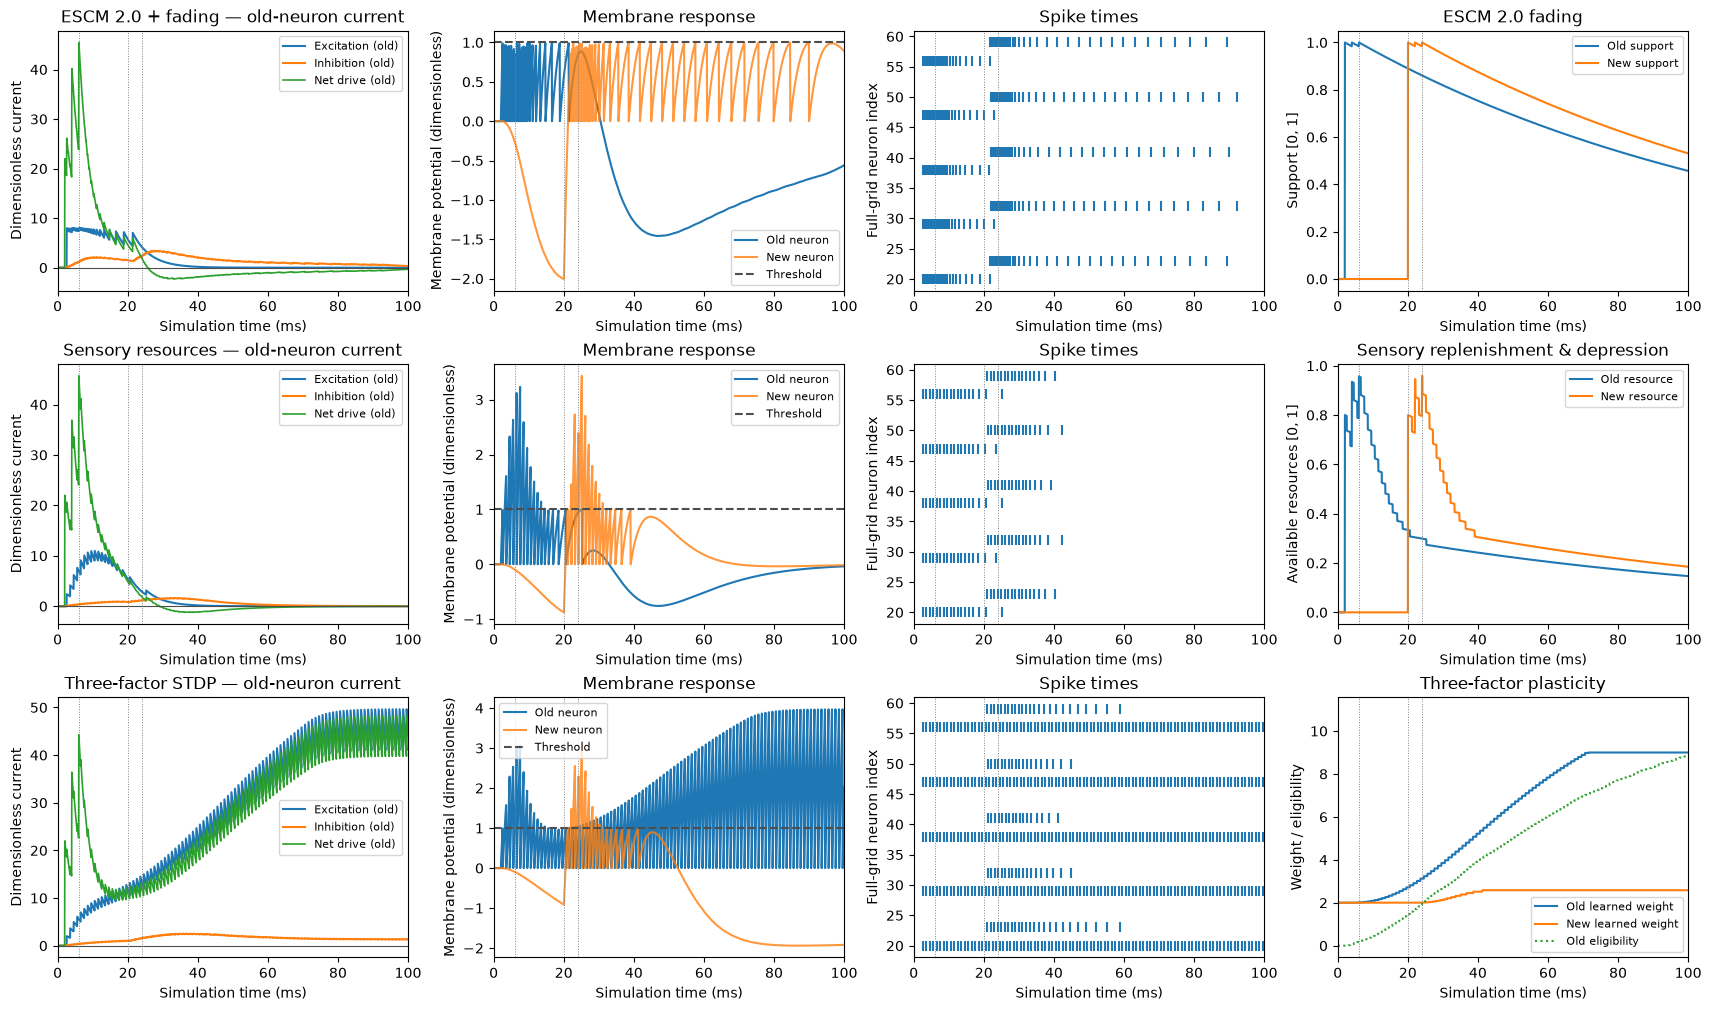

No-camera-input fading control:  33%|███▎      | 1/3 [00:00<00:00,  2.64it/s]WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
No-camera-input fading control:  67%|██████▋   | 2/3 [00:00<00:00,  2.54it/s]WARNING    't' is an internal variable of group 'synapses_1', but also exists in the run namespace with the value array([0.0000e+00, 5.0000e-02, 1.0000e-01, ..., 1.9985e+02, 1.9990e+02,
       1.9995e+02], shape=(4000,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
No-camera-input fading control: 100%|██████████| 3/3 [00:01<00:00,  2.43it/s]


,model,total_spikes,last_spike_ms,post_camera_spikes,spikes_30_60,spikes_60_120,spikes_180_260,min_isi_ms
0,ESCM 2.0 + fading,54,89.20,34,12,8,0,0.25
1,Sensory resources,20,28.25,12,0,0,0,1.00
2,Three-factor STDP,298,299.55,290,30,60,80,1.00


In [9]:
old, new = shapes['vertical']
trace_ids = [int(old[2]), int(new[2])]
traces = {}
for name, cfg in tqdm(models.items(), desc='Current and plasticity diagnostics'):
    traces[name] = simulate(pulse_schedule(old, new), **cfg,
                            duration_ms=200., trace_ids=trace_ids)

fig, axes = plt.subplots(len(models), 4, figsize=(17, 10), constrained_layout=True)
for row, (name, run) in enumerate(traces.items()):
    t = run['time']
    ax = axes[row, 0]
    ax.plot(t, run['Iexc'][0], label='Excitation (old)', lw=1.5)
    ax.plot(t, run['Iinh'][0], label='Inhibition (old)', lw=1.5)
    ax.plot(t, run['Iext'][0]+run['Iexc'][0]-run['Iinh'][0],
            label='Net drive (old)', lw=1.2)
    ax.axhline(0, color='0.3', lw=0.8)
    ax.legend(fontsize=8)
    ax.set(ylabel='Dimensionless current', title=name+' — old-neuron current', xlim=(0, 100))
    ax = axes[row, 1]
    ax.plot(t, run['v'][0], label='Old neuron')
    ax.plot(t, run['v'][1], label='New neuron', alpha=0.8)
    ax.axhline(1, ls='--', color='0.3', label='Threshold')
    ax.set(ylabel='Membrane potential (dimensionless)', title='Membrane response', xlim=(0, 100))
    ax.legend(fontsize=8)
    ax = axes[row, 2]
    mask = np.isin(run['i'], np.r_[old, new])
    ax.scatter(run['t'][mask], run['i'][mask], marker='|', s=50)
    ax.set(ylabel='Full-grid neuron index', title='Spike times', xlim=(0, 100))
    ax = axes[row, 3]
    if 'resource' in run:
        ax.plot(t, run['resource'][0], label='Old resource')
        ax.plot(t, run['resource'][1], label='New resource')
        ax.set(ylabel='Available resources [0, 1]', title='Sensory replenishment & depression')
    elif 'w' in run:
        ax.plot(t, run['w'][0], label='Old learned weight')
        ax.plot(t, run['w'][1], label='New learned weight')
        ax.plot(t, run['eligibility'][0], ':', label='Old eligibility')
        ax.set(ylabel='Weight / eligibility', title='Three-factor plasticity')
    else:
        ax.plot(t, run['support'][0], label='Old support')
        ax.plot(t, run['support'][1], label='New support')
        ax.set(ylabel='Support [0, 1]', title='ESCM 2.0 fading')
    ax.set(xlim=(0, 100))
    ax.legend(fontsize=8)
    for a in axes[row]:
        for onset in (6, 20, 24):
            a.axvline(onset, color='0.5', ls=':', lw=0.7)
        a.set_xlabel('Simulation time (ms)')
plt.show()

fade_rows = []
for name, cfg in tqdm(models.items(), desc='No-camera-input fading control'):
    run = simulate(solo_schedule, **cfg, duration_ms=300., n_neurons=1)
    fade_rows.append(dict(model=name, **solo_metrics(run)))
display(pd.DataFrame(fade_rows).round(3))

## 10. Scientific interpretation and limitations

After executing, use the tables and traces to answer **all** of the following:

1. **Synaptic mechanics:** Does SRR resource monotonically decrease after the last camera event? Does the learned 3F weight persist when modulation vanishes? Does each candidate actually transmit *additively*?
2. **Recruitment and persistence:** Are all five pixels active in each isolated control? Is late persistence present? Does the model become silent without new camera input?
3. **Competition:** Does inhibition terminate previously active old pixels without extinguishing the new structure? Is any apparent suppression merely spontaneous fading? Does termination happen early or late?
4. **Generalization:** What is the strict replacement score in the six validation geometries and 16 timing conditions? Do numerical classifications agree across 0.1, 0.05 and 0.025 ms?
5. **Neuronal realism:** Are minimum interspike intervals consistent with 1 ms refractoriness? Are membrane and excitatory currents bounded in the observed simulations? (Absolute refractoriness limits rate; it does not by itself guarantee low current amplitude.)

### What this experiment **cannot** establish

- A successful **autaptic** 3F rule is **not** evidence that general three-factor STDP has been faithfully tested: on one neuron, pre/post times coincide. A stronger future test would require distinct recurrent neurons, adding a new architectural factor to control.
- SRR is a **proposed sensory-conditioned synaptic mechanism**. It is not conventional autonomous-recovery STD, and neural hardware must support camera-triggered updates of the recurrent synapse's state (or a local equivalent).
- Searching and choosing a model on vertical/horizontal geometries does not establish universal performance. Five older geometries were explored before this notebook; only the *within-notebook* holdout is clean.
- No finite grid search proves that a plasticity model cannot work. No finite recording proves indefinite persistence is impossible. Thresholds, pulse timing and the chosen time constants all affect outcomes.

### Sources

- Frémaux, N., & Gerstner, W. (2016). *Neuromodulated Spike-Timing-Dependent Plasticity, and Theory of Three-Factor Learning Rules*. **Frontiers in Neural Circuits**, 9, 85. DOI: [10.3389/fncir.2015.00085](https://doi.org/10.3389/fncir.2015.00085). Eligibility traces and a third modulatory factor; this notebook uses a simplified event-sampled realization.
- Tsodyks, M., Pawelzik, K., & Markram, H. (1998). *Neural networks with dynamic synapses*. **Neural Computation**, 10(4), 821–835. DOI: [10.1162/089976698300017502](https://doi.org/10.1162/089976698300017502). Conventional depression/recovery framework; SRR explicitly modifies recovery to depend on camera events and uses resource leakage.
- [Brian2 user guide — Synapses](https://brian2.readthedocs.io/en/stable/user/synapses.html). Event-driven synaptic dynamics, pre/post updates, and implementation semantics.

**Decision rule:** prefer a new model over ESCM 2.0 if it gives better held-out recruitment, rapid *true* suppression, and acceptable fading and firing rates. Do not select a model merely because its mean excitatory current or isolated last-spike time happens to match the reference.